Business Objective: An e-commerce retailer manages a diverse portfolio of products across numerous subcategories, each contributing differently to overall profitability. Without a structured approach to evaluating product margins, profit contributions, and similarities between product subcategories, it may be difficult to identify which products should receive greater commercial attention and where potential cross-selling opportunities exist.
Steps:
1.EDA and clean. Explore and change odject datatype from object to datetime. Check for NaNs in columns.
2.Merge dataset. Inspect numeric and non-numeric columns, outliers and drop columns. Consider impact of duplicated rows upon merging.
3.Checking profit columns. To confirm derivation of profit. profit['net_sales']-profit['shipping_cost']-profit['product_cost']
4.Prepare dataset for unsupervised ML model. Drops columns and one-hot encoding for non-numeric columns. Scaling numeric-columns.
5.Use Cosine Similarity to investigate similarity of sub-category pairs. Drop rows and re-modeling Cosine Similarity to improve result.
6.Use Kmeans and Algomerative Clustering. Compare results of clustering by product-subcategory.
7.Evaluate clustering models.

###EDA

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dataset=pd.read_csv('C:\Codefiles\Content\dataset_statistics.csv')
sales=pd.read_csv('C:\Codefiles\Content\ecommerce_sales_customer_analytics_150K.csv')
customer=pd.read_csv('C:\Codefiles\Content\customer_master.csv')
product=pd.read_csv('C:\Codefiles\Content\product_catalog.csv')
order=pd.read_csv('C:\Codefiles\Content\order_items.csv')

In [3]:
#converting object to numerica
dataset['Total Profit'] = pd.to_numeric(
    dataset['Total Profit']
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False),
    errors='coerce'
)

dataset['Total Revenue'] = pd.to_numeric(
    dataset['Total Revenue']
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False),
    errors='coerce'
)

dataset['Overall Profit Margin']=dataset['Total Profit']/dataset['Total Revenue']*100
print(dataset['Total Revenue'].map('{:.2f}'.format))
print(dataset['Total Profit'])
dataset['Overall Profit Margin']

0    177134263.74
Name: Total Revenue, dtype: object
0    76146395.76
Name: Total Profit, dtype: float64


0    42.987954
Name: Overall Profit Margin, dtype: float64

In [6]:
# order.info()
# # product_profit.info()
# product.info()
sales.info()
combine[combine['is_repeat_customer'] == False][['order_date','order_id','customer_id','loyalty_points_earned','loyalty_points_redeemed','customer_acquisition_cost','is_repeat_customer','profit_y']].sort_values(by='customer_id')
# combine[['order_date','order_id','customer_id','loyalty_points_earned','loyalty_points_redeemed','customer_acquisition_cost','is_repeat_customer']].sort_values(by='customer_id')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  object 
 1   order_date                138116 non-null  object 
 2   order_time                138116 non-null  object 
 3   order_status              138116 non-null  object 
 4   sales_channel             138116 non-null  object 
 5   customer_id               138116 non-null  object 
 6   customer_name             138116 non-null  object 
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  object 
 9   customer_segment          138116 non-null  object 
 10  customer_type             138116 non-null  object 
 11  customer_city             138116 non-null  object 
 12  customer_state            138116 non-null  object 
 13  customer_country          138116 non-null  o

,order_date,order_id,customer_id,loyalty_points_earned,loyalty_points_redeemed,customer_acquisition_cost,is_repeat_customer,profit_y
351313,2025-10-04,ORD-645594,CUST-000024,100,27,12.03,False,16.94
351314,2025-10-04,ORD-645594,CUST-000024,100,27,12.03,False,64.14
351315,2025-10-04,ORD-645594,CUST-000024,100,27,12.03,False,126.86
351316,2025-10-04,ORD-645594,CUST-000024,100,27,12.03,False,213.76
385566,2025-09-12,ORD-495707,CUST-000117,169,53,79.40,False,168.12
...,...,...,...,...,...,...,...,...
393528,2023-03-28,ORD-137764,CUST-024902,254,236,17.25,False,446.76
393529,2023-03-28,ORD-137764,CUST-024902,254,236,17.25,False,492.36
393530,2023-03-28,ORD-137764,CUST-024902,254,236,17.25,False,91.00
62810,2024-08-27,ORD-591022,CUST-024973,190,182,25.09,False,142.56


In [ ]:
# combine.customer_lifetime_value.sum()/combine.customer_id.nunique()

Redo Merge Dataset for Power BI (2nd Round)

In [5]:
combine = sales.merge(order, on='order_id', how='left') \
              .merge(product, on='product_id', how='left')

combine = combine.merge(customer, on='customer_id', how='left')

combine[combine.order_status=='Completed']['profit_y'].sum()
combine = combine[combine['order_status'] == 'Completed']
combine = combine.drop(
    columns=[col for col in combine.columns if col.endswith('_x')]
)

combine['profit_margin']=combine['profit_y']/combine['net_sales_y']
overall_margin=combine['profit_y'].sum()/combine['net_sales_y'].sum()
print(combine['profit_margin'].mean())
print(overall_margin)

combine['sub_profit_margin'] = (
    combine.groupby('product_subcategory')['profit_y'].transform('sum')
    / combine.groupby('product_subcategory')['net_sales_y'].transform('sum')
)

combine[['product_subcategory','sub_profit_margin']].sort_values(by='sub_profit_margin',ascending=False)


check = combine.groupby('product_subcategory').agg(
    avg_sub_profit_margin=('sub_profit_margin', 'mean'),
    total_profit=('profit_y', 'sum'),
    total_net_sales=('net_sales_y', 'sum')
)

check['profit_margin_sum_ratio'] = (
    check['total_profit'] / check['total_net_sales']
)

check['difference'] = (
    check['avg_sub_profit_margin'] - check['profit_margin_sum_ratio']
)

check['negligible'] = check['difference'].abs() < 0.0001

check.sort_values('difference', key=abs, ascending=False)
check.negligible.value_counts()

# combine.to_csv('combine.csv', index=False)

0.4487425776686851
0.41559731147700857


negligible
True    117
Name: count, dtype: int64

In [7]:
#EDA
sales[['customer_country','customer_segment','sales_channel','campaign_name','coupon_code','discount_amount','is_repeat_customer','customer_order_count']].sort_values(by='customer_order_count',ascending=False)

,customer_country,customer_segment,sales_channel,campaign_name,coupon_code,discount_amount,is_repeat_customer,customer_order_count
43882,USA,Consumer,Website,NaN,SAVE35,199.19,True,20
126168,USA,Consumer,Website,Default_Campaign,NaN,0.00,True,20
108049,USA,Consumer,Website,Default_Campaign,NaN,164.82,True,20
138013,USA,Consumer,Marketplace,Insta_Stories,NaN,130.94,True,20
128015,USA,Consumer,Mobile App,NaN,NaN,184.77,True,20
...,...,...,...,...,...,...,...,...
72905,UK,Premium,Mobile App,Default_Campaign,SAVE10,130.91,False,1
71482,USA,Premium,Website,NaN,SAVE26,0.00,False,1
83488,USA,VIP,Mobile App,NaN,SAVE16,0.00,False,1
77564,Australia,Consumer,Website,NaN,NaN,585.01,False,1


In [8]:
#EDA
sales.warehouse.value_counts()
sales.return_status.value_counts(normalize=True)
sales.customer_rating.describe()
sales.campaign_name.value_counts(normalize=True)
sales.loyalty_points_earned.describe()
sales.profit.describe()

count    138116.000000
mean        551.322046
std         516.300936
min       -1281.590000
25%         190.757500
50%         408.395000
75%         752.845000
max        7083.680000
Name: profit, dtype: float64

2.Checking profit columns. To confirm derivation of profit. profit['net_sales']-profit['shipping_cost']-profit['product_cost']

In [9]:
#checking profit numbers
profit=sales.groupby(['customer_id','customer_type','customer_segment'])[['net_sales','shipping_cost','product_cost','profit','profit_margin_percentage','customer_lifetime_value']].sum()
profit['profit2']=profit['net_sales']-profit['shipping_cost']-profit['product_cost']
profit['check']=profit['profit']-profit['profit2']

profit['negligible']=np.where((profit['check'] >= -1) & (profit['check'] <= 1),
    'negligible',
    'not negligible'
) 
profit.negligible.value_counts()
profit.profit.describe()
profit

,,,net_sales,shipping_cost,product_cost,profit,profit_margin_percentage,customer_lifetime_value,profit2,check,negligible
customer_id,customer_type,customer_segment,,,,,,,,,
CUST-000001,Loyal,Consumer,9924.84,375.65,5654.79,3894.40,391.92,100132.56,3894.40,-4.547474e-13,negligible
CUST-000002,Loyal,Consumer,18138.96,189.11,8811.26,9138.59,527.26,181389.60,9138.59,1.818989e-12,negligible
CUST-000003,Loyal,Consumer,7798.59,109.70,3816.91,3871.98,354.50,54590.13,3871.98,-4.547474e-13,negligible
CUST-000004,Loyal,VIP,11218.95,162.95,7310.30,3745.70,228.16,78532.65,3745.70,9.094947e-13,negligible
CUST-000005,Loyal,Consumer,10063.97,227.74,5814.57,4021.66,317.27,80511.76,4021.66,0.000000e+00,negligible
...,...,...,...,...,...,...,...,...,...,...,...
CUST-024996,Loyal,Consumer,10068.54,197.02,6431.43,3440.09,282.49,70479.78,3440.09,0.000000e+00,negligible
CUST-024997,Returning,Consumer,1282.82,67.38,592.66,622.78,142.21,3848.46,622.78,-1.136868e-13,negligible
CUST-024998,Loyal,Business,5675.09,215.30,2830.43,2629.36,392.58,45400.72,2629.36,4.547474e-13,negligible


In [10]:
#select only completed. Drop pending and cancelled orders.
sales1=sales[sales['order_status']=='Completed']
sales1= sales1.merge(customer, on='customer_id', how='left')
sales1=sales1.drop(columns=['return_status','return_reason'])
sales1 = sales1.drop(columns=[
    col for col in sales1.columns
    if col.endswith('_y')
])
sales1.columns = sales1.columns.str.replace('_x$', '', regex=True)

In [11]:
#EDA
sales.loc[sales['order_status'] != 'Completed',['order_status','delivery_days','estimated_delivery_days','return_status','return_reason','customer_rating','review_sentiment','customer_review']]
completed_sales = sales[sales['order_status'] == 'Completed']
completed_sales.iloc[:,34:]

,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,5,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,2,544.62,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,6,2474.52,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8
...,...,...,...,...,...,...,...,...,...,...,...,...
138109,3,280.60,38.27,16.97,20.54,279.84,137.21,122.09,43.63,2380.81,True,3
138110,4,1150.65,163.53,69.10,9.60,1065.82,704.12,352.10,33.04,5273.57,True,6
138111,1,212.83,8.84,14.28,6.15,224.42,101.77,116.50,51.91,18182.63,True,14
138114,13,2040.01,174.60,130.58,84.39,2080.38,1042.40,953.59,45.84,8047.00,True,5


In [12]:
#Convert object to datetime. drop column.
sales.order_date= pd.to_datetime(sales.order_date)
sales['order_time'] = pd.to_datetime(sales['order_time'],format='%H:%M:%S').dt.time
# sales=sales.drop(columns='customer_postal_code')

In [13]:
completed_list=sales.loc[(sales.order_status=='Completed'), 'order_id'].tolist()
# print(sales['order_id'].nunique())
print(sales[sales.order_status!='Completed']['profit'].sum())
print(sales[sales.order_status=='Completed']['profit'].sum())
print(sales['profit'].sum())
# print(sales['profit'].sum())
# product_profit.total_product_profit.sum()
# non_completed_list
len(completed_list)

16387926.73
59758469.03
76146395.75999999


113559

In [14]:
#Built profitability by product csv for visualisation.
# 1. Bring order_status into order_items
order_with_status = order.merge(
    sales[['order_id', 'order_status']],
    on='order_id',
    how='left',
    validate='many_to_one'
)

# 2. Keep completed orders only
completed = order_with_status.loc[
    order_with_status['order_status'].eq('Completed')
].copy()

# 3. Aggregate profit and sales once per product
product_profit3 = (
    completed.groupby('product_id')
    .agg(
        total_product_profit=('profit', 'sum'),
        total_net_sales=('net_sales', 'sum')
    )
)

product_profit3['product_margin']=product_profit3['total_product_profit']/product_profit3['total_net_sales']
product_profit3.total_product_profit.sum()

np.float64(65164085.24999999)

In [15]:
#Check Profit & Profit Margin.
print(sales[sales.order_status=='Completed']['profit'].sum()/(sales[sales.order_status=='Completed']['net_sales'].sum()))
print(completed['profit'].sum()/completed['net_sales'].sum())
completed['profit'].sum()
print('Filtered sales net sales:',
      sales.loc[sales['order_status'] == 'Completed', 'net_sales'].sum())
print('Completed net sales:', completed['net_sales'].sum())
print(sales[sales.order_status=='Completed']['profit'].sum())
print(sales[sales.payment_status=='Pending']['profit'].sum())

0.4144257535559877
0.41559731147700857
Filtered sales net sales: 144195838.5
Completed net sales: 156796214.63
59758469.03
7309245.21


In [16]:
# Method A: filter using completed order IDs
profit_by_id = sales.loc[
    sales['order_id'].isin(completed_list), 'profit'
].sum()

# Method B: filter individual rows by status
profit_by_status = sales.loc[
    sales['order_status'].eq('Completed'), 'profit'
].sum()

print('Filter by completed order IDs:', profit_by_id)
print('Filter by row status:', profit_by_status)

Filter by completed order IDs: 59758469.03
Filter by row status: 59758469.03


In [17]:
#Built profitability Bins.
bins = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
labels = ['20-29%', '30-39%', '40-49%', '50-59%', '60-69%']

product_profit3['profit_margin_bin'] = pd.cut(
    product_profit3['product_margin'],
    bins=bins,
    labels=labels,
    right=False
)
product_profit3

,total_product_profit,total_net_sales,product_margin,profit_margin_bin
product_id,,,,
PROD-000001,82987.17,383695.40,0.216284,20-29%
PROD-000002,208532.64,514716.83,0.405141,40-49%
PROD-000003,42724.72,175650.20,0.243238,20-29%
PROD-000004,260939.50,626745.33,0.416341,40-49%
PROD-000005,240547.09,617996.46,0.389237,30-39%
...,...,...,...,...
PROD-001171,36430.02,58412.44,0.623669,60-69%
PROD-001172,53825.34,129473.75,0.415724,40-49%
PROD-001173,11288.36,23059.79,0.489526,40-49%


In [18]:
#Built profitability by product csv for visualisation (1st round)
product_profit3= product_profit3.merge(product, on='product_id', how='left')

product_profit3.to_csv('C:\Codefiles\Content\product_profitability.csv', index=False)
product_profit3.total_product_profit.sum()

np.float64(65164085.24999999)

In [19]:
# Built profitability by product csv for visualisation. (0th round)
# product_profit= order2.merge(product, on='product_id', how='left')
# product_profit.to_csv('C:\Codefiles\Content\product_profitability.csv', index=False)
# product_profit

In [20]:
#for merging od sales, order, product table.
order1=order[['order_id','product_id']]
order2=order1[order1['order_id'].isin(completed_list)]
order2.to_csv("oid.csv", index=False)

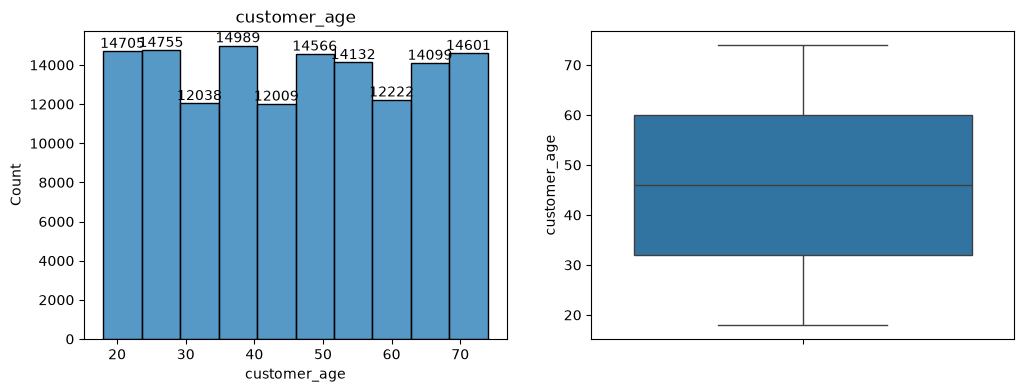

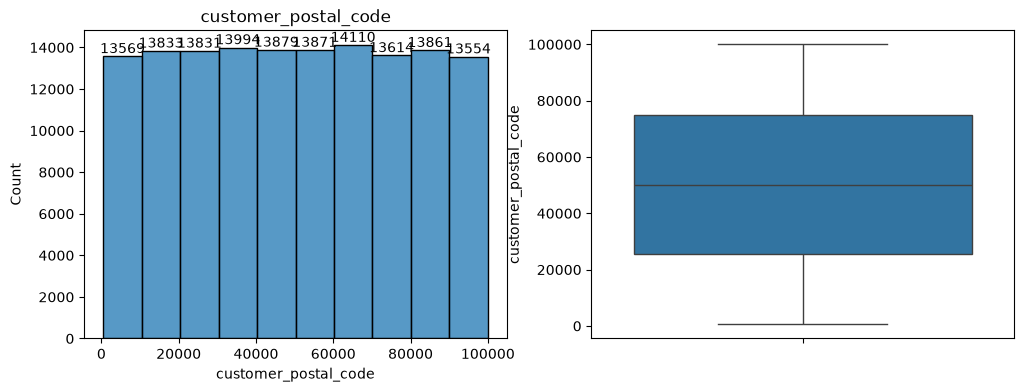

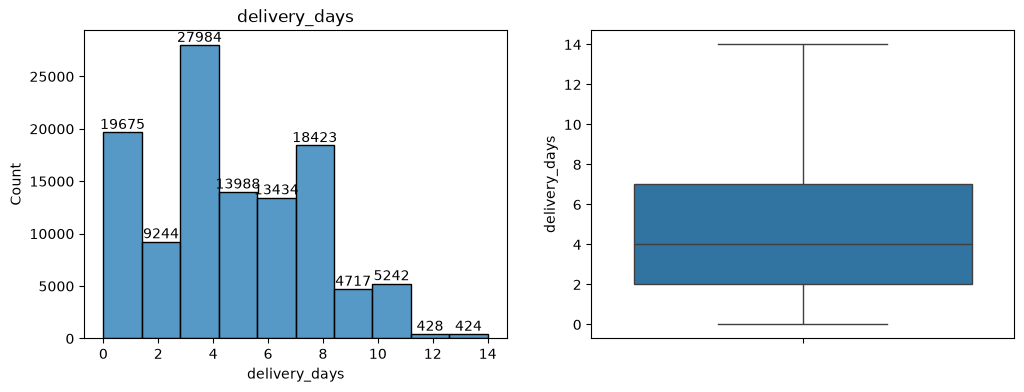

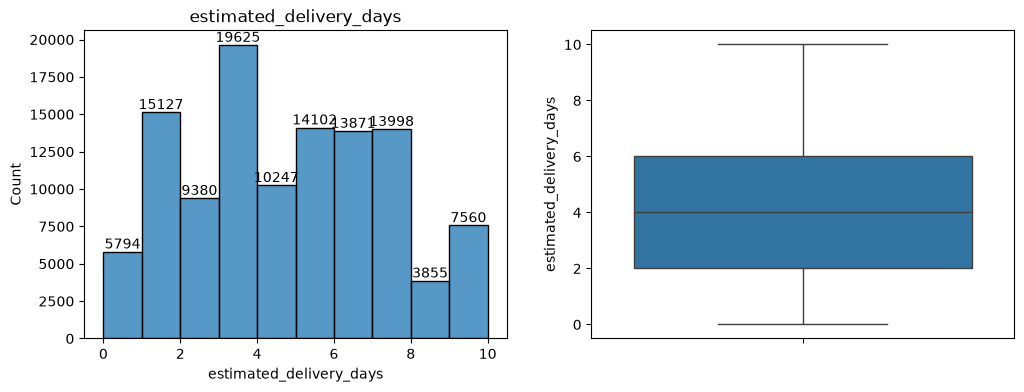

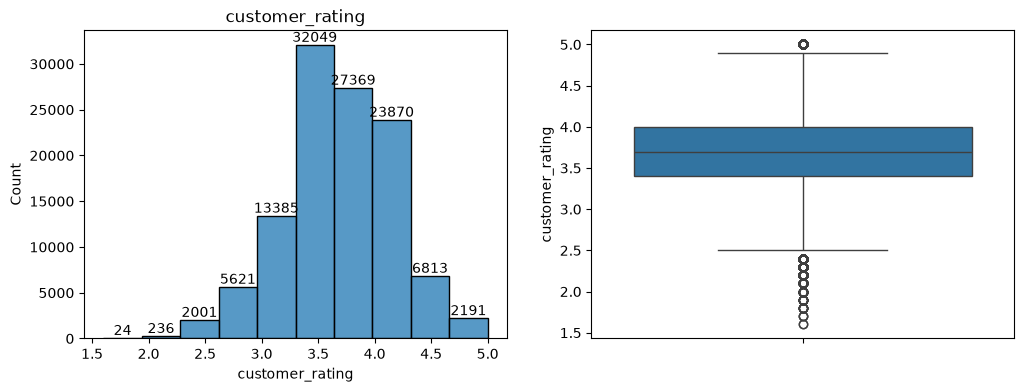

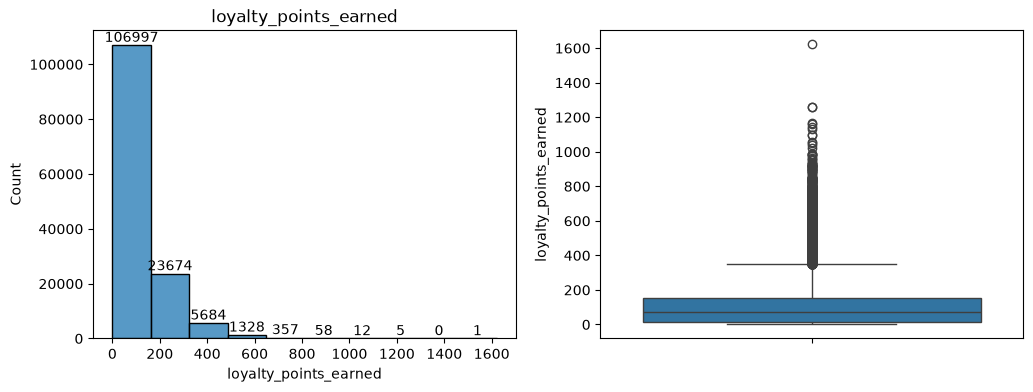

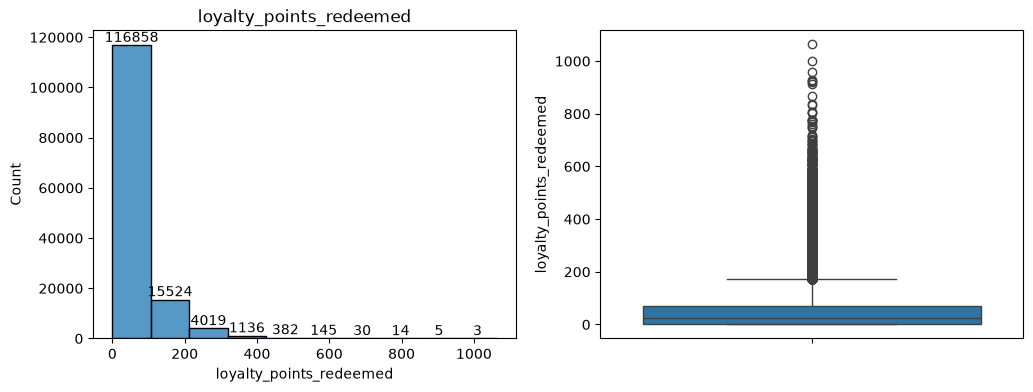

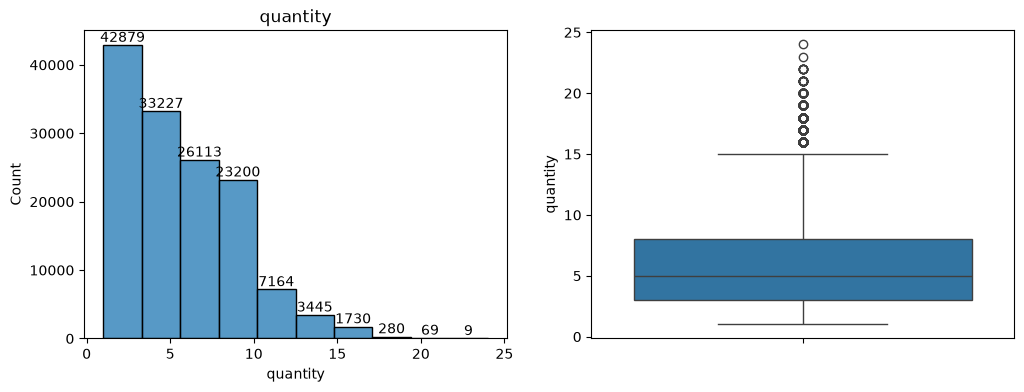

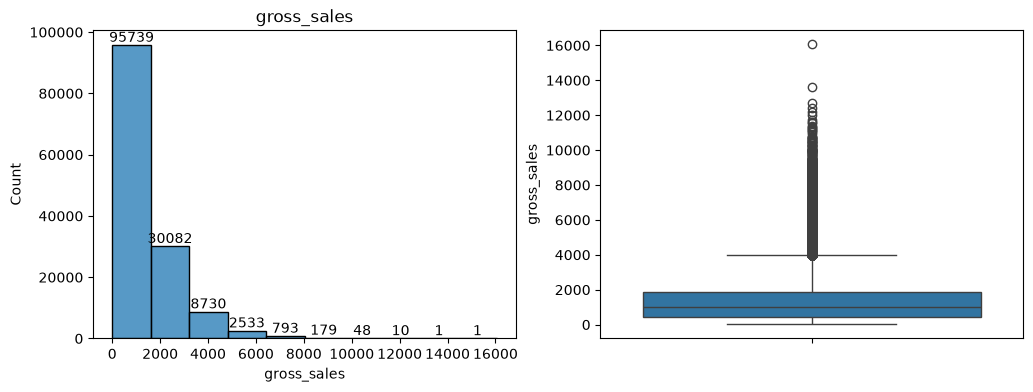

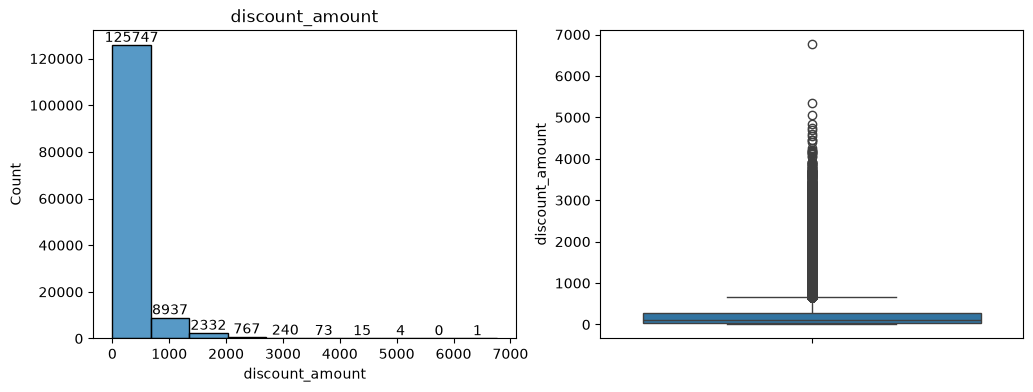

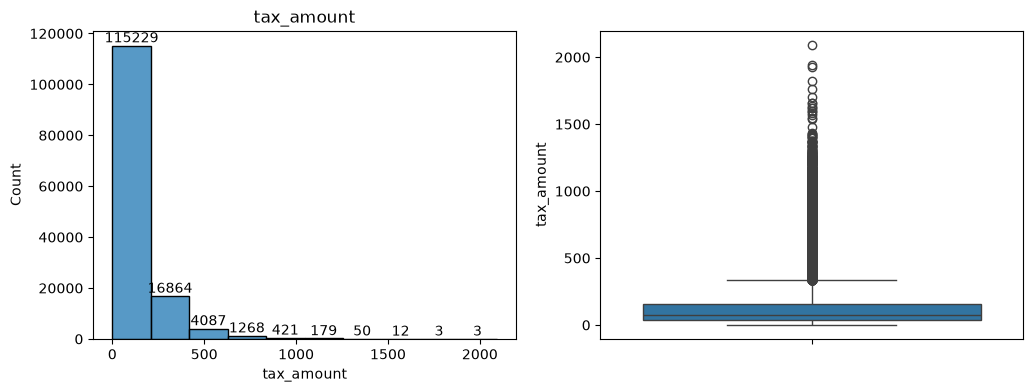

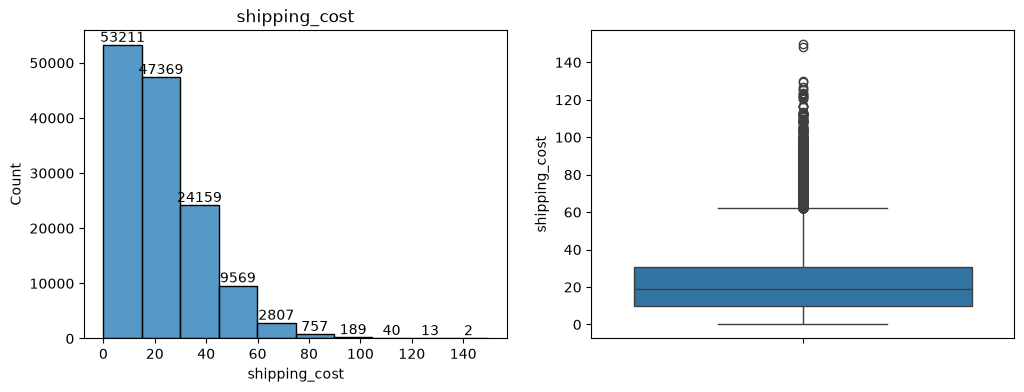

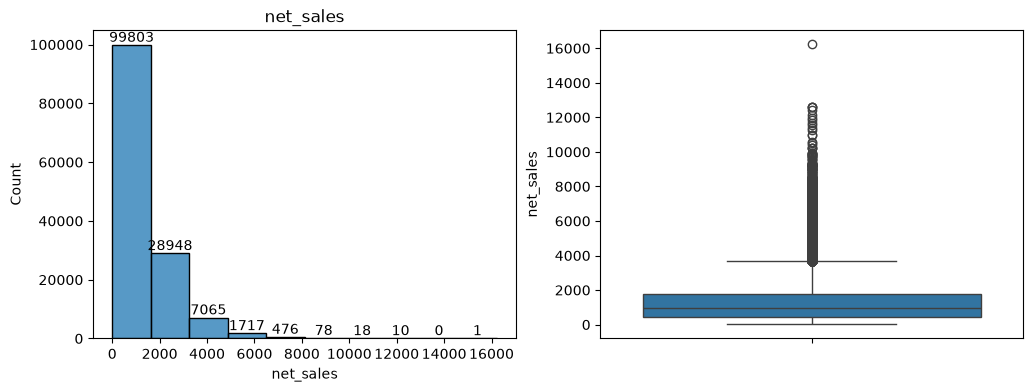

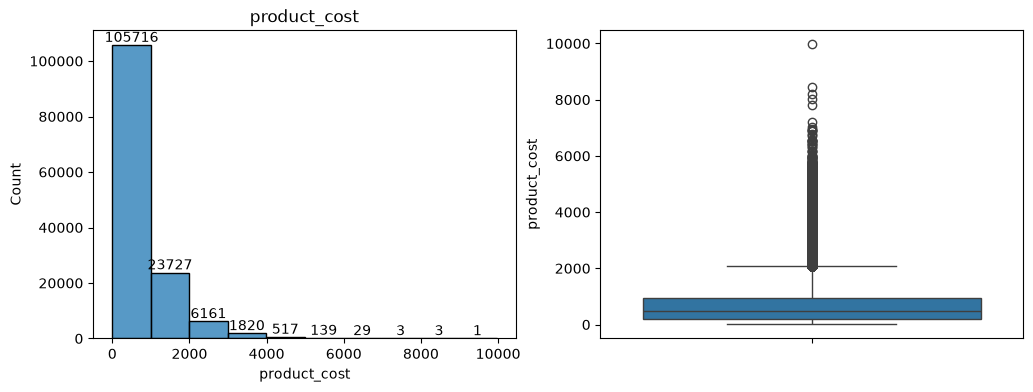

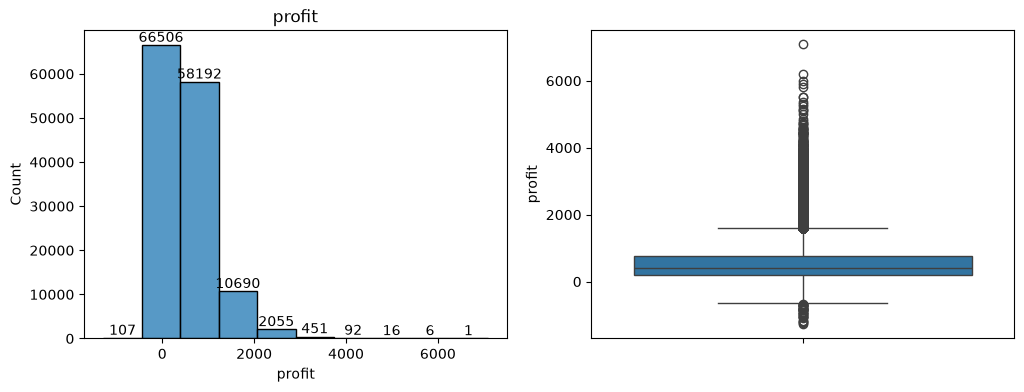

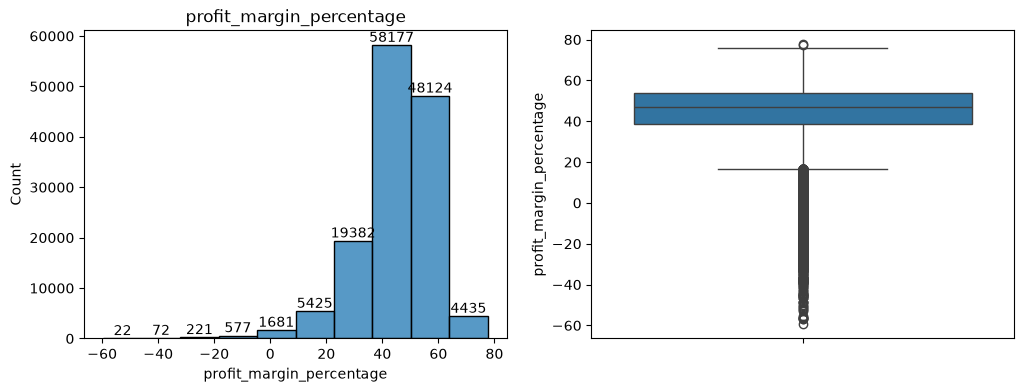

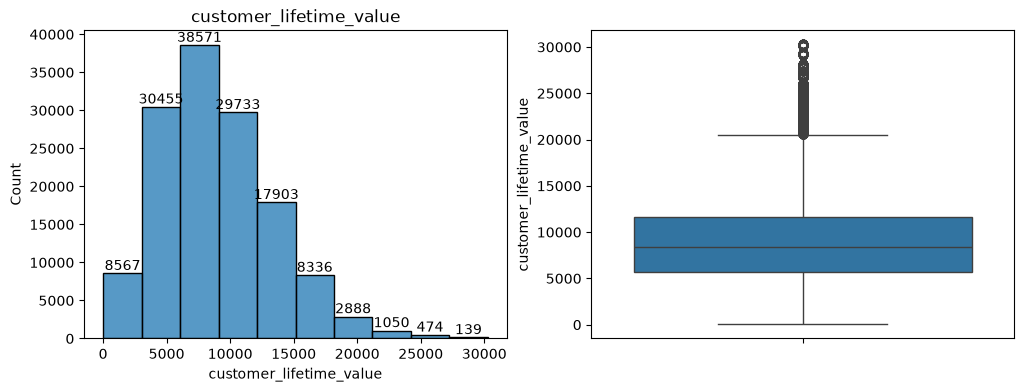

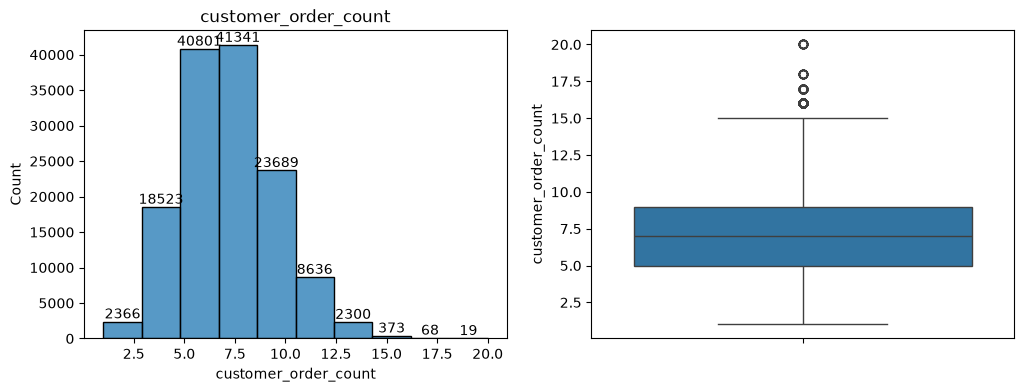

In [21]:
#EDA
def plot_histograms(sales):
    num_cols = sales.select_dtypes(include='number').columns

    for col in num_cols:
        fig, ax = plt.subplots(1, 2, figsize=(12, 4))
        sns.histplot(data=sales, x=col, bins=10, kde=False, ax=ax[0])
        for container in ax[0].containers:
            ax[0].bar_label(container)
        ax[0].set_title(f'{col}')
        ax[0].set_xlabel(col)
          
        sns.boxplot(sales, y=col, ax=ax[1])
        # ax[1].set_xlabel(col)
        plt.show()
        
plot_histograms(sales)

In [22]:
# sns.pairplot(sales)

In [23]:
# #EDA

# def plot_countsplots(sales):
#     cat_cols = sales.select_dtypes(exclude='number').columns

#     for col in cat_cols:
        
#         fig, ax = plt.subplots(figsize=(15, 5))
#         order = sales[col].value_counts().index
        
#         sns.countplot(data=sales, ax=ax, order=order, x=col)
        
#         ax.tick_params(axis='x', labelsize=8, labelrotation=45)
        
#         for container in ax.containers:
#           ax.bar_label(container, fmt='{:,.0f}', fontsize=7)
        
#         plt.show()

# plot_countsplots(sales)

3.Merge dataset. Inspect numeric and non-numeric columns, outliers and drop columns. Consider impact of duplicated rows upon merging.

In [25]:
#Merging completd sales, order and product datasets 'Old' merged
# merged = completed_sales.merge(order1, on='order_id', how='left') \
#               .merge(product, on='product_id', how='left')

Round 2 Dataset to rerun KMEANs clustering. Use combine dataset with more columns.

In [185]:
from sklearn.model_selection import train_test_split

# Preserve the complete dataset before splitting
merged_all = combine.copy()

# Split unique order IDs, not individual product rows
merged_ids = combine['order_id'].drop_duplicates()

train_ids, test_ids = train_test_split(
    merged_ids,
    test_size=0.20,
    random_state=42
)

# Create training and test datasets from the full dataset
merged = merged_all[
    merged_all['order_id'].isin(train_ids)
].copy()

test_orders = merged_all[
    merged_all['order_id'].isin(test_ids)
].copy()


test_level = merged_all[
    merged_all['order_id'].isin(test_ids)
].copy()

# Your downstream analysis uses training data
merged1 = combine.copy()

#create for Markett Based-Analysis
merged_mba=merged.copy

4.Prepare dataset for unsupervised ML model. Drops columns and one-hot encoding for non-numeric columns. Scaling numeric-columns.
Initial split for ML learning. Cosine Similarity, Algomerative & KMEANS

In [27]:
# #Train_test_split
# from sklearn.model_selection import train_test_split

# # Preserve the complete dataset before splitting
# merged_all = merged.copy()

# # Split unique order IDs, not individual product rows
# merged_ids = merged_all['order_id'].drop_duplicates()

# train_ids, test_ids = train_test_split(
#     merged_ids,
#     test_size=0.20,
#     random_state=42
# )

# # Create training and test datasets from the full dataset
# merged = merged_all[
#     merged_all['order_id'].isin(train_ids)
# ].copy()

# test_orders = merged_all[
#     merged_all['order_id'].isin(test_ids)
# ].copy()


# test_level = merged_all[
#     merged_all['order_id'].isin(test_ids)
# ].copy()

# # Your downstream analysis uses training data
# merged1 = merged.copy()

In [28]:
#EDA on duplicated rows after merging sales and product dataset. Create another Merged1 dateset to exclude order_id with more than 5 product_Id for 2nd Machine Learning run.  

# completed_sales.select_dtypes(include='number').info()
# numeric_data.info()
# non_numeric.info()
# non_numeric.coupon_code.value_counts()
# investigate=pd.DataFrame(merged.groupby('order_id')['product_id'].count())
# investigate.sort_values(by='product_id',ascending=False)
# per=pd.DataFrame(investigate.product_id.value_counts(normalize=True))
# per[per.index<=5].sum()

# id_exclude=investigate[investigate['product_id']>5].index.tolist()
# merged1=merged1[~merged1['order_id'].isin(id_exclude)]
# merged1

In [179]:
merged.columns

Index(['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel',
       'customer_id', 'customer_type', 'payment_method', 'payment_status',
       'currency', 'shipping_method', 'warehouse', 'delivery_days',
       'estimated_delivery_days', 'delivery_status', 'return_status',
       'return_reason', 'customer_rating', 'review_sentiment',
       'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code',
       'loyalty_points_earned', 'loyalty_points_redeemed',
       'profit_margin_percentage', 'customer_lifetime_value',
       'is_repeat_customer', 'customer_order_count', 'product_id',
       'quantity_y', 'discount_percentage', 'discount_amount_y',
       'gross_sales_y', 'tax_amount_y', 'shipping_cost_y', 'net_sales_y',
       'product_cost_y', 'profit_y', 'product_name', 'product_category',
       'product_subcategory', 'brand', 'supplier', 'unit_price_y',
       'product_cost', 'product_rating', 'customer_name_y', 'customer_age_y',
       'gender_y', '

In [186]:
remove_cols = [
    # Identifiers
    'customer_id',
    'product_id',

    # Names and free text
    'customer_name_y',
    'product_name',
    'customer_review',

    # High-cardinality location details (depending on objective)
    'customer_city_y',
    'customer_state_y',
    'customer_country_y',

    # Dates and times (extract useful features first if needed)
    'order_date',
    'order_time',
    
    # updates
    'product_category',
    'product_cost'
    
    
]
merged_mba = merged.drop(columns=remove_cols, errors='ignore')


In [181]:
#Visualize duplicated rows after merging sales and product dataset. 

# sns.histplot(x="product_id", data=investigate)
# fig, ax = plt.subplots(1, 2, figsize=(12, 4))
# sns.histplot(data=investigate, x="product_id", bins=20, kde=False, ax=ax[0])
# for container in ax[0].containers:
#     ax[0].bar_label(container)
#     ax[0].set_title(f'{"product_id"}')
#     # ax[0].set_xlabel(col)
          
# sns.boxplot(investigate, x="product_id", ax=ax[1])
#     # ax[1].set_xlabel(col)
# plt.show()
remove_cols = [
    # Identifiers
    'order_id',
    'customer_id',
    'product_id',

    # Names and free text
    'customer_name_y',
    'product_name',
    'customer_review',

    # High-cardinality location details (depending on objective)
    'customer_city_y',
    'customer_state_y',
    'customer_country_y',

    # Dates and times (extract useful features first if needed)
    'order_date',
    'order_time',
    
    # updates
    'product_category',
    'product_cost'
    
    
]
merged = merged.drop(columns=remove_cols, errors='ignore')
test_orders = test_orders.drop(columns=remove_cols, errors='ignore')
merged1 = merged1.drop(columns=remove_cols, errors='ignore')

test_orders.shape

(65622, 46)

In [132]:
#Select columns and feature engineering for Machine learning.

# merged.info()
# merged=merged.drop(columns=['return_status','return_reason'])
numeric_data=merged.select_dtypes(include='number')
non_numeric=merged.select_dtypes(exclude='number')
# non_numeric.info()
non_numeric = pd.get_dummies(
    non_numeric,
    columns=non_numeric.columns,
    dtype=int
)
# numeric_data.info()
non_numeric.shape

(261406, 405)

In [133]:
#for Machine learning run 2.

# merged
# merged1=merged1.drop(columns=['return_status','return_reason'])
numeric_data1=merged1.select_dtypes(include='number')
non_numeric1=merged1.select_dtypes(exclude='number')
# non_numeric.info()
non_numeric1 = pd.get_dummies(
    non_numeric1,
    columns=non_numeric1.columns,
    dtype=int
)
# numeric_data.info()
merged1.shape

(327028, 46)

In [134]:
from sklearn.preprocessing import StandardScaler

std = StandardScaler()
numeric_std=std.fit_transform(numeric_data)
numeric_std=pd.DataFrame(numeric_std, columns=numeric_data.columns)
numeric_std

,delivery_days,estimated_delivery_days,customer_rating,loyalty_points_earned,loyalty_points_redeemed,profit_margin_percentage,customer_lifetime_value,customer_order_count,quantity_y,discount_percentage,...,net_sales_y,product_cost_y,profit_y,unit_price_y,product_rating,customer_age_y,customer_postal_code_y,customer_acquisition_cost,profit_margin,sub_profit_margin
0,-0.552805,-0.500181,-0.397120,-0.469813,-0.381380,-0.542188,0.728431,1.631047,-0.126268,1.368626,...,-0.211338,-0.247360,-0.107531,-0.004181,1.604010,0.551796,1.255002,1.429776,0.267456,0.073872
1,-0.552805,-0.500181,-0.397120,-0.469813,-0.381380,-0.542188,0.728431,1.631047,0.702166,1.546989,...,0.186350,0.356017,-0.104389,0.165880,-0.975837,0.551796,1.255002,1.429776,-1.039930,0.250169
2,1.937079,2.199935,-0.186939,0.396339,1.123643,-3.484224,0.856975,1.631047,1.530600,2.390225,...,2.368331,4.252026,-1.042275,2.027155,-0.259213,-1.209355,0.430536,1.162367,-3.192386,-0.526893
3,1.937079,2.199935,-0.186939,0.396339,1.123643,-3.484224,0.856975,1.631047,1.530600,1.341435,...,-0.627376,-0.540750,-0.613281,-0.852056,0.457411,-1.209355,0.430536,1.162367,-0.072688,0.449322
4,-0.552805,-0.500181,1.284327,-0.858368,-0.713196,-0.097871,-0.685432,-0.406626,0.702166,-0.615390,...,-0.758495,-0.665059,-0.734426,-0.951752,-0.975837,1.402007,-1.061973,0.458052,1.299015,0.345192
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261401,-1.264200,-1.657374,-0.817482,0.453003,-0.819852,0.188431,-0.261837,-0.814160,-0.126268,-0.088850,...,-0.371423,-0.324077,-0.367811,-0.429511,-0.689188,0.005232,1.204732,-1.005538,-0.217505,0.035703
261402,-1.264200,-1.657374,-0.817482,0.453003,-0.819852,0.188431,-0.261837,-0.814160,2.359033,-0.557177,...,0.179882,0.020974,0.370839,-0.503418,-1.262487,0.005232,1.204732,-1.005538,0.329177,0.743359
261403,-1.264200,-1.657374,-0.817482,0.453003,-0.819852,0.188431,-0.261837,-0.814160,0.702166,-0.201459,...,-0.513175,-0.518913,-0.468804,-0.767921,-0.832513,0.005232,1.204732,-1.005538,0.178754,0.657928
261404,0.158591,0.271280,0.863965,0.040164,-0.594691,-0.020429,-1.145943,-0.814160,-0.954702,-0.730946,...,1.039969,0.729893,1.353271,3.482560,1.604010,-1.087896,1.335442,-1.203669,0.267330,-1.773475


In [135]:
#Prepare and Scale Test_ids

# test_orders=test_orders.drop(columns=['return_status','return_reason'])
numeric_datat=test_orders.select_dtypes(include='number')
# numeric_datat=numeric_datat.drop(columns=['net_sales', 'gross_sales','product_cost_x', 'profit','estimated_delivery_days'])
# numeric_datat=numeric_datat.drop(columns=['product_cost_y'])
non_numerict=test_orders.select_dtypes(exclude='number')
# non_num_colt=test_orders[['sales_channel','gender','customer_segment','customer_type','customer_country','shipping_method','marketing_channel','campaign_name']]
non_numerict = pd.get_dummies(
    non_numerict,
    columns=non_numerict.columns,
    dtype=int
)

std = StandardScaler()
numeric_stt=std.fit_transform(numeric_datat)
numeric_stt=pd.DataFrame(numeric_stt, columns=numeric_datat.columns)
# numeric_stt

test_orders = test_orders.reset_index(drop=True)
numeric_stt = numeric_stt.reset_index(drop=True)
non_numerict = non_numerict.reset_index(drop=True)

test_data=pd.concat([numeric_stt,non_numerict], axis=1)
test_data['product_subcategory'] = test_orders.loc[test_data.index, 'product_subcategory']
test_group=test_data.groupby('product_subcategory').mean()
test_group.shape

# test_group.columns
# numeric_datat.info()

(117, 429)

Check for col difference

In [52]:
# cols_not_in_df2 = pairwise_group.columns.difference(test_group.columns)
# print(cols_not_in_df2)

In [139]:
#Scaling data for Machine learning run 2.
from sklearn.preprocessing import StandardScaler

std = StandardScaler()
numeric_std1=std.fit_transform(numeric_data1)
numeric_std1=pd.DataFrame(numeric_std1, columns=numeric_data1.columns)

In [138]:
#Prepare dataset for cosine similarity.

merged = merged.reset_index(drop=True)
numeric_std = numeric_std.reset_index(drop=True)
non_numeric = non_numeric.reset_index(drop=True)


pairwise_data=pd.concat([numeric_std,non_numeric], axis=1)
pairwise_data['product_subcategory'] = merged.loc[pairwise_data.index, 'product_subcategory']
pairwise_group=pairwise_data.groupby('product_subcategory').mean()
pairwise_group.shape

(117, 429)

In [53]:
#Prepare dataset for cosine similarity 2.

# numeric_std1 = numeric_std1.reset_index(drop=True)
# non_num_dum1 = non_num_dum1.reset_index(drop=True)
# merged1 = merged1.reset_index(drop=True)

# pairwise_data1=pd.concat([numeric_std1,non_num_dum1], axis=1)
# pairwise_data1['product_subcategory'] = (
#     merged1['product_subcategory']
# )

# pairwise_group1=pairwise_data1.groupby('product_subcategory').mean()
# pairwise_group1.info()

In [140]:
# Cosine similarity run 1.
from sklearn.metrics.pairwise import cosine_similarity
cosine_matrix=cosine_similarity(pairwise_group)
similar_df=pd.DataFrame(cosine_matrix, index=pairwise_group.index, columns=pairwise_group.index)
similar_df

product_subcategory,Academic,Accessories,Action Figures,Air Conditioners,Aquariums,Arts & Crafts,Audiobooks,Baby Food,Baby Gear,Bags,...,Toasters,Tools,Toys,Vacuum Cleaners,Vitamins,Washing Machines,Watches,Women's Clothing,Writing Instruments,Yoga
product_subcategory,,,,,,,,,,,,,,,,,,,,,
Academic,1.000000,0.729042,0.861657,0.309623,0.848297,0.845477,0.901986,0.842784,0.834075,0.840798,...,0.292435,0.442195,0.838915,0.229887,0.765903,0.068755,0.505471,0.784484,0.820285,0.761847
Accessories,0.729042,1.000000,0.712605,0.579051,0.798460,0.792029,0.707745,0.724261,0.730018,0.612698,...,0.460797,0.681673,0.806871,0.534580,0.835175,0.355092,0.639766,0.803701,0.766098,0.740113
Action Figures,0.861657,0.712605,1.000000,0.349265,0.851401,0.845640,0.859012,0.859496,0.874498,0.859438,...,0.426587,0.528272,0.825396,0.254782,0.744832,0.216421,0.588517,0.825053,0.841734,0.795794
Air Conditioners,0.309623,0.579051,0.349265,1.000000,0.425069,0.497750,0.288028,0.467851,0.433105,0.326098,...,0.799053,0.830443,0.546364,0.912277,0.640361,0.797827,0.811919,0.547767,0.519802,0.638669
Aquariums,0.848297,0.798460,0.851401,0.425069,1.000000,0.851259,0.839714,0.825876,0.843042,0.786070,...,0.425726,0.587432,0.847413,0.351857,0.794035,0.249262,0.602591,0.841878,0.841007,0.795682
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Washing Machines,0.068755,0.355092,0.216421,0.797827,0.249262,0.299707,0.053957,0.299074,0.325810,0.193020,...,0.888270,0.799159,0.313327,0.791207,0.395895,1.000000,0.770000,0.436357,0.359238,0.499740
Watches,0.505471,0.639766,0.588517,0.811919,0.602591,0.658626,0.484753,0.660371,0.658584,0.587499,...,0.849864,0.846105,0.676003,0.765519,0.699221,0.770000,1.000000,0.718852,0.699497,0.786886
Women's Clothing,0.784484,0.803701,0.825053,0.547767,0.841878,0.834145,0.764957,0.812256,0.841709,0.760890,...,0.581399,0.707075,0.833192,0.477977,0.809916,0.436357,0.718852,1.000000,0.830559,0.828888


In [ ]:
# Cosine similarity run 2.
# from sklearn.metrics.pairwise import cosine_similarity
# cosine_matrix=cosine_similarity(pairwise_group1)
# similar_df1=pd.DataFrame(cosine_matrix, index=pairwise_group1.index, columns=pairwise_group1.index)
# similar_df1

In [141]:
#Result 1
import numpy as np

matrix = similar_df.to_numpy()

# Exclude diagonal (each subcategory compared with itself)
values = matrix[np.triu_indices_from(matrix, k=1)]

print("Minimum:", values.min())
print("Mean:", values.mean())
print("Median:", np.median(values))
print("Maximum:", values.max())
print("Pairs >= 0.90:", (values >= 0.90).sum())
print("Total pairs:", len(values))

Minimum: -0.20609564864930596
Mean: 0.6324795654084011
Median: 0.7429071092111892
Maximum: 0.9635001616146494
Pairs >= 0.90: 96
Total pairs: 6786


In [57]:
#Result 2 changing data set for cosine similarity or merged1 dataset
# import numpy as np

# matrix = similar_df1.to_numpy()

# # Exclude diagonal (each subcategory compared with itself)
# values = matrix[np.triu_indices_from(matrix, k=1)]

# print("Minimum:", values.min())
# print("Mean:", values.mean())
# print("Median:", np.median(values))
# print("Maximum:", values.max())
# print("Pairs >= 0.90:", (values >= 0.90).sum())
# print("Total pairs:", len(values))

In [142]:
upper_triangle = np.triu(
    np.ones(similar_df.shape, dtype=bool),
    k=1
)

similar_pairs = (
    similar_df
    .rename_axis(index='subcategory_1', columns='subcategory_2')
    .where(upper_triangle)
    .stack()
    .reset_index(name='cosine_similarity')
)

# Exclude similarity values equal to 1
similar_pairs = similar_pairs[
    ~np.isclose(similar_pairs['cosine_similarity'], 1.0)
]

# Recreate top20
top20 = similar_pairs.nlargest(
    20, 'cosine_similarity'
).sort_values('cosine_similarity')

top20['pair'] = (
    top20['subcategory_1'].astype(str)
    + ' + '
    + top20['subcategory_2'].astype(str)
)

similar_pairs.sort_values(by='cosine_similarity', ascending=False).head(20)

,subcategory_1,subcategory_2,cosine_similarity
6539,Smart Watches,TVs,0.963500
5117,Laptops,TVs,0.963110
4516,Gaming Consoles,Laptops,0.962998
6666,TVs,Tablets,0.962675
2299,Cameras,Smartphones,0.962605
6560,Smartphones,TVs,0.962552
6540,Smart Watches,Tablets,0.961911
6533,Smart Watches,Smartphones,0.961554
2305,Cameras,TVs,0.960736
2298,Cameras,Smart Watches,0.960248


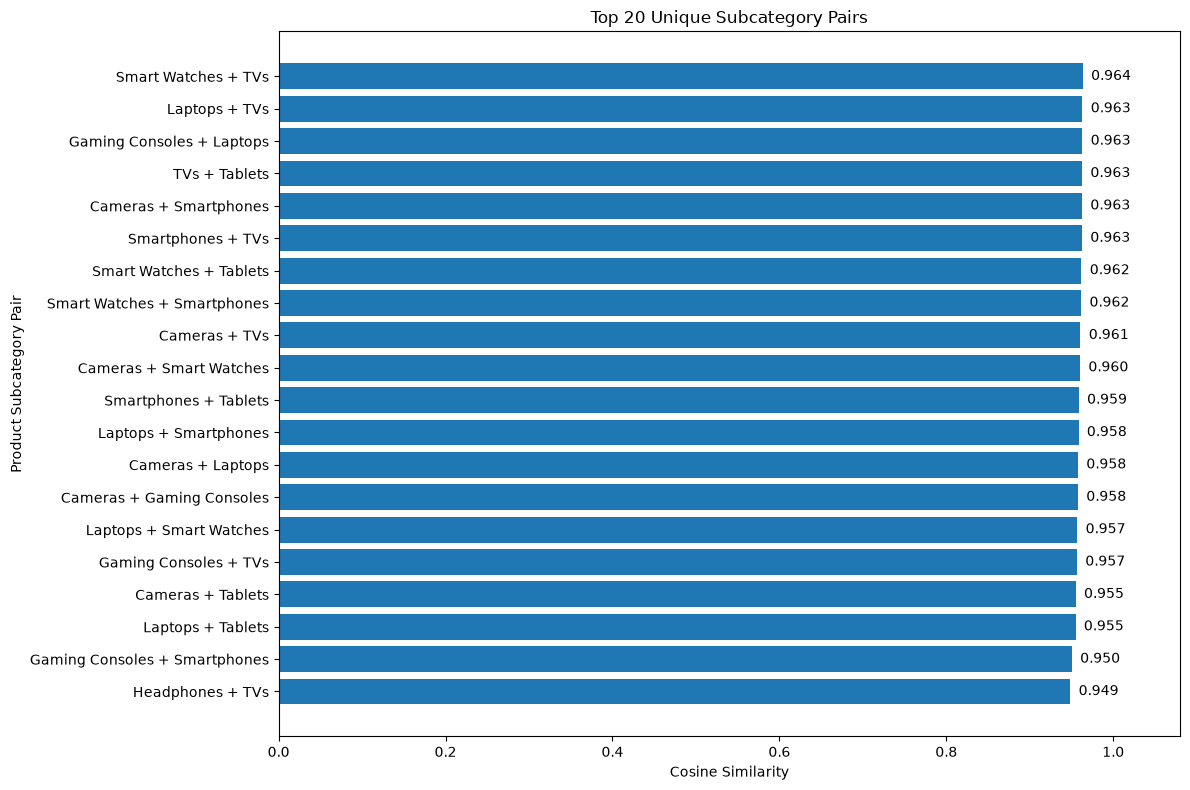

In [143]:
#Visualise result 1
plt.figure(figsize=(12, 8))

bars = plt.barh(
    top20['pair'],
    top20['cosine_similarity']
)

# Display similarity values at the end of each bar
for bar in bars:
    value = bar.get_width()

    plt.text(
        value + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.3f}',
        va='center'
    )

plt.xlabel('Cosine Similarity')
plt.ylabel('Product Subcategory Pair')
plt.title('Top 20 Unique Subcategory Pairs')
plt.xlim(0, 1.08)
plt.tight_layout()
plt.show()

In [144]:
distance = 1 - similar_df.to_numpy()

# Ensure symmetry and zero diagonal
distance = (distance + distance.T) / 2
np.fill_diagonal(distance, 0)

In [145]:
#pivot to AgglomerativeClustering for more meaning clusters.

from sklearn.cluster import AgglomerativeClustering

n_groups = round(len(similar_df) / 5.5)

model = AgglomerativeClustering(
    n_clusters=n_groups,
    metric='precomputed',
    linkage='average'
)

labels = model.fit_predict(distance)

group1 = pd.DataFrame({
    'product_subcategory': similar_df.index,
    'group': labels + 1
})

group1 = group1.sort_values(
    ['group', 'product_subcategory']
).reset_index(drop=True)

group1

,product_subcategory,group
0,Accessories,1
1,Collars & Leashes,1
2,Oral Care,1
3,Outdoor Toys,1
4,Puzzles,1
...,...,...
112,Car Seats,19
113,Pet Beds,19
114,Women's Clothing,19
115,Clothing,20


In [146]:
 #Result of AgglomerativeClustering.
grouped_subcategories = (
    group1.groupby('group')['product_subcategory']
    .apply(list)
)

for group_id, subcategories in grouped_subcategories.items():
    print(f"Group {group_id}: {', '.join(subcategories)}")

Group 1: Accessories, Collars & Leashes, Oral Care, Outdoor Toys, Puzzles
Group 2: Toasters, Watches
Group 3: Bedding, Calendars, First Aid, Mail & Shipping, Massagers, Shoes, Toys
Group 4: Baby Food, Baby Gear, Diapers, Office Furniture, Paper Products, Presentation, Technology, Writing Instruments
Group 5: Cycling, Running
Group 6: Medical Devices, Men's Clothing, Supplements, Swimming
Group 7: Air Conditioners, Gemstones, Refrigerators, Vacuum Cleaners
Group 8: Furniture, Storage, Yoga
Group 9: Camping, Car Accessories, Chains, Maintenance, Microwaves, Team Sports, Tires, Tools
Group 10: Bathroom Accessories, Decor
Group 11: Blenders, Bracelets, Cameras, Coffee Makers, Earrings, Gaming Consoles, Headphones, Laptops, Necklaces, Pendants, Rings, Smart Watches, Smartphones, TVs, Tablets, Washing Machines
Group 12: Academic, Action Figures, Aquariums, Arts & Crafts, Audiobooks, Bath & Body, Beverages, Blood Pressure Monitors, Board Games, Children's Books, Comics, Dairy, Deodorants, Dol

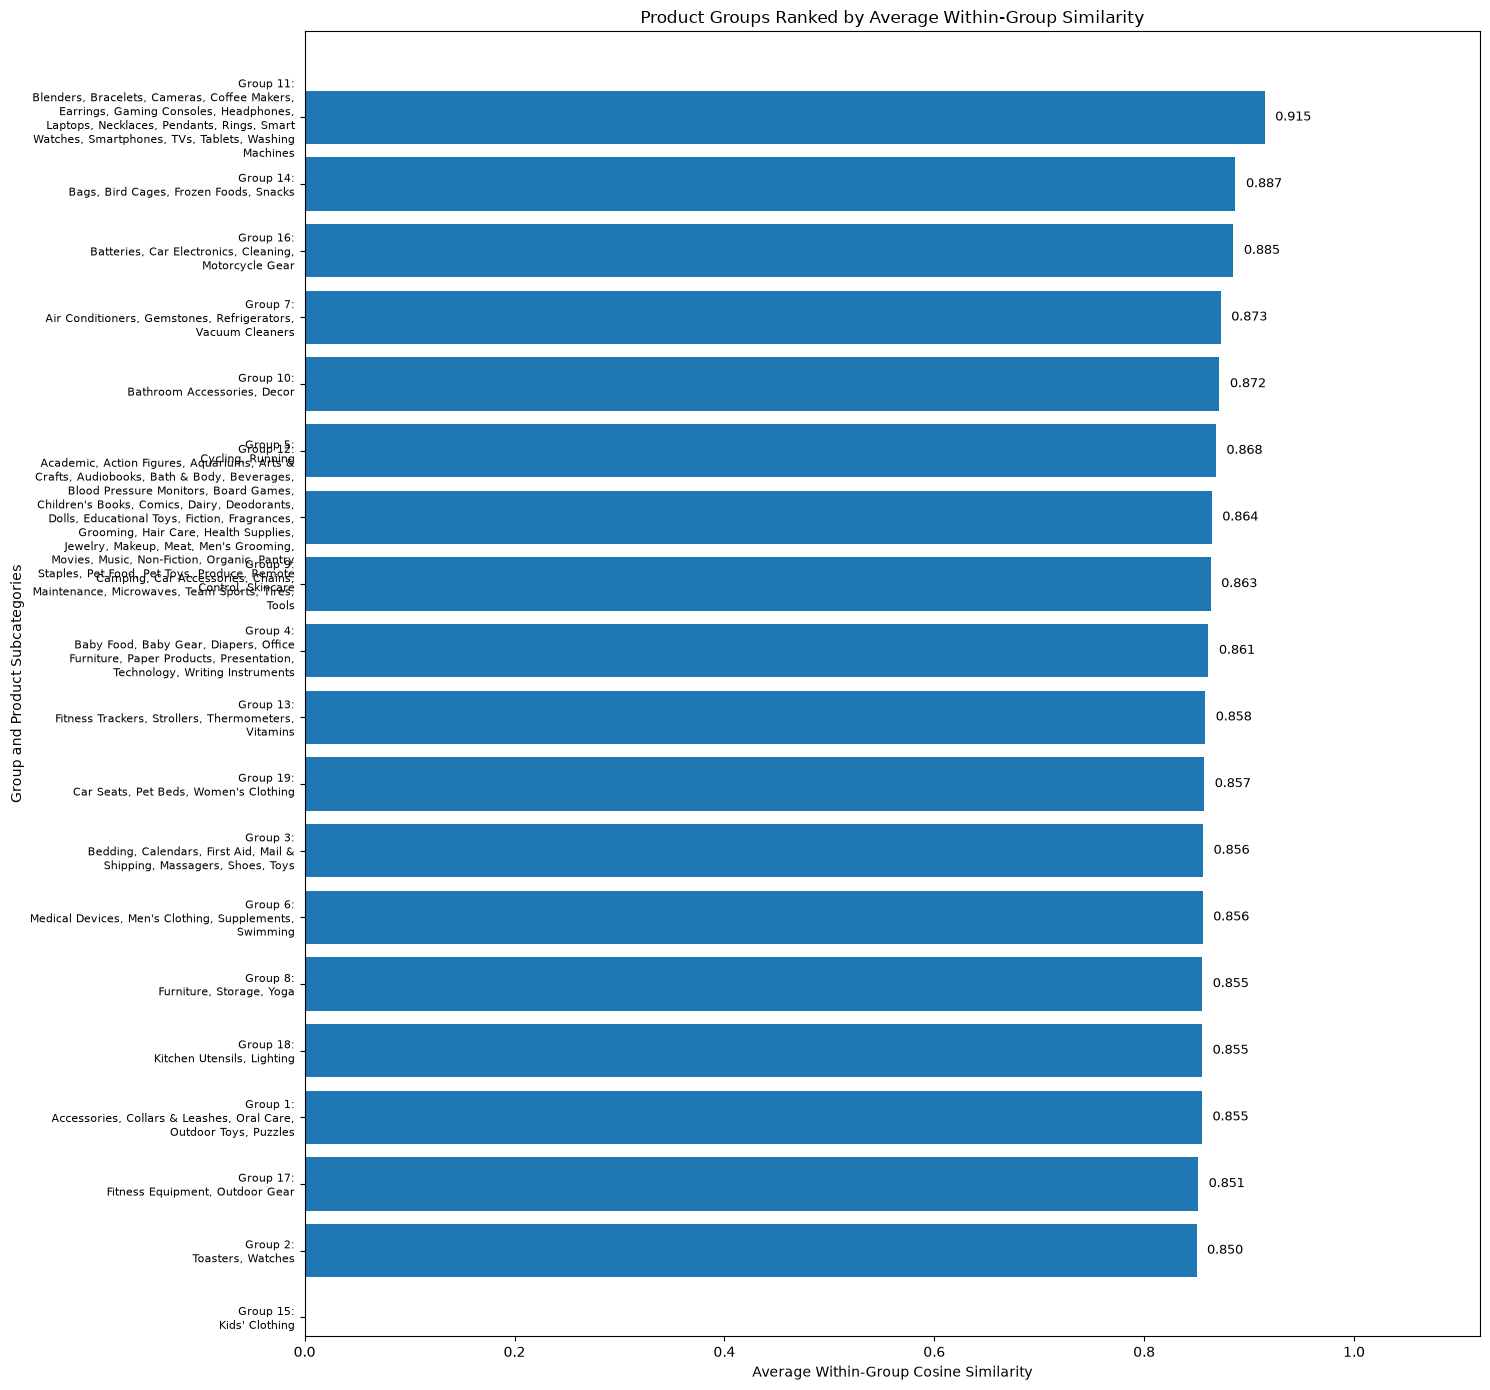

In [147]:
 # Visualize result of AgglomerativeClustering.
import textwrap

# Convert similarity matrix to a DataFrame
similarity_df = pd.DataFrame(
    similar_df.to_numpy(),
    index=similar_df.index,
    columns=similar_df.columns
)

# Calculate average within-group similarity
group_scores = []

for group_id, subcategories in (
    group1.groupby('group')['product_subcategory']
):
    # Similarities between subcategories in this group
    group_similarity = similarity_df.loc[
        subcategories, subcategories
    ].to_numpy()

    # Exclude diagonal (self-similarity)
    mask = ~np.eye(len(subcategories), dtype=bool)

    if len(subcategories) > 1:
        avg_similarity = group_similarity[mask].mean()
    else:
        # A single-item group has no within-group comparisons
        avg_similarity = np.nan

    group_scores.append({
        'Group': group_id,
        'Product Subcategories': ', '.join(subcategories),
        'Average Cosine Similarity': avg_similarity
    })

group_table = pd.DataFrame(group_scores)

# Sort highest similarity first
plot_data = group_table.sort_values(
    'Average Cosine Similarity',
    ascending=False,
    na_position='last'
).copy()

# Wrap labels
plot_data['label'] = plot_data.apply(
    lambda row: (
        f"Group {row['Group']}:\n"
        + textwrap.fill(
            row['Product Subcategories'],
            width=45
        )
    ),
    axis=1
)

# Plot
fig, ax = plt.subplots(figsize=(15, 14))

bars = ax.barh(
    plot_data['label'],
    plot_data['Average Cosine Similarity']
)

# Add scores at the end of each bar
for bar in bars:
    value = bar.get_width()

    if np.isfinite(value):
        ax.text(
            value + 0.01,
            bar.get_y() + bar.get_height() / 2,
            f'{value:.3f}',
            va='center',
            fontsize=9
        )

ax.invert_yaxis()
ax.set_xlabel('Average Within-Group Cosine Similarity')
ax.set_ylabel('Group and Product Subcategories')
ax.set_title('Product Groups Ranked by Average Within-Group Similarity')
ax.set_xlim(0, 1.12)
ax.tick_params(axis='y', labelsize=8)

plt.tight_layout()
plt.show()

In [148]:
#Use Kmeans for clustering.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# pairwise_group already has product_subcategory as its index
X = pairwise_group.copy()

# Choose number of clusters
n_groups = round(len(X) / 5.5)
# n_groups = 7
# Fit K-Means
model = KMeans(
    n_clusters=n_groups,
    random_state=42,
    n_init=10
)

labels = model.fit_predict(X)

# Create cluster assignments
groups = pd.DataFrame({
    'product_subcategory': X.index,
    'group': labels + 1
})

# Sort results
groups = groups.sort_values(
    ['group', 'product_subcategory']
).reset_index(drop=True)

groups

C:\Users\ringa\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,product_subcategory,group
0,Action Figures,1
1,Board Games,1
2,Dairy,1
3,Fiction,1
4,Makeup,1
...,...,...
112,Children's Books,21
113,Comics,21
114,Movies,21
115,Music,21


In [155]:
n_groups = round(len(similar_df) / 5.5)

ward_model = AgglomerativeClustering(
    n_clusters=n_groups,
    metric='euclidean',
    linkage='ward'
)

labels_ward = ward_model.fit_predict(X)

group2 = pd.DataFrame({
    'product_subcategory': X.index,
    'group': labels_ward + 1
})

group2 = groups.sort_values(
    ['group', 'product_subcategory']
).reset_index(drop=True)

group2

,product_subcategory,group
0,Action Figures,1
1,Board Games,1
2,Dairy,1
3,Fiction,1
4,Makeup,1
...,...,...
112,Children's Books,21
113,Comics,21
114,Movies,21
115,Music,21


In [156]:
grouped_subcategories = (
    group2.groupby('group')['product_subcategory']
    .apply(list)
)

for group_id, subcategories in grouped_subcategories.items():
    print(f"Group {group_id}: {', '.join(subcategories)}")

Group 1: Action Figures, Board Games, Dairy, Fiction, Makeup, Meat, Organic, Produce
Group 2: Gemstones, Refrigerators, Rings, Toasters
Group 3: Cameras, Gaming Consoles, Laptops
Group 4: Bedding, Car Seats, Clothing
Group 5: Accessories, Collars & Leashes, Cookware, Cycling, First Aid, Kitchen Utensils, Lighting, Medical Devices, Men's Clothing, Running, Shoes, Strollers, Supplements, Swimming, Vitamins, Women's Clothing
Group 6: Car Electronics, Cleaning, Motorcycle Gear
Group 7: Aquariums, Baby Food, Baby Gear, Bath & Body, Diapers, Educational Toys, Jewelry, Office Furniture, Paper Products, Pet Beds, Presentation, Remote Control, Technology, Writing Instruments
Group 8: Camping, Car Accessories, Chains, Microwaves
Group 9: Blenders, Coffee Makers, Earrings, Washing Machines
Group 10: Arts & Crafts, Blood Pressure Monitors, Calendars, Dolls, Fragrances, Grooming, Hair Care, Health Supplies, Mail & Shipping, Massagers, Oral Care, Outdoor Toys, Pantry Staples, Pet Food, Pet Toys, Puz

In [159]:
#compare result of Kmeans and AgglomerativeClustering. cntrl + F 'group2
from sklearn.metrics import adjusted_rand_score

comparison = groups.merge(
    group2,
    on='product_subcategory',
    suffixes=('_kmeans', '_agglo')
)

ari = adjusted_rand_score(
    comparison['group_kmeans'],
    comparison['group_agglo']
)

print('Adjusted Rand Index:', round(ari, 4))

Adjusted Rand Index: 1.0


In [112]:
#21 clusters
grouped_subcategories = (
    groups.groupby('group')['product_subcategory']
    .apply(list)
)

for group_id, subcategories in grouped_subcategories.items():
    print(f"Group {group_id}: {', '.join(subcategories)}")

Group 1: Action Figures, Board Games, Dairy, Fiction, Makeup, Meat, Organic, Produce
Group 2: Gemstones, Refrigerators, Rings, Toasters
Group 3: Cameras, Gaming Consoles, Laptops
Group 4: Bedding, Car Seats, Clothing
Group 5: Accessories, Collars & Leashes, Cookware, Cycling, First Aid, Kitchen Utensils, Lighting, Medical Devices, Men's Clothing, Running, Shoes, Strollers, Supplements, Swimming, Vitamins, Women's Clothing
Group 6: Car Electronics, Cleaning, Motorcycle Gear
Group 7: Aquariums, Baby Food, Baby Gear, Bath & Body, Diapers, Educational Toys, Jewelry, Office Furniture, Paper Products, Pet Beds, Presentation, Remote Control, Technology, Writing Instruments
Group 8: Camping, Car Accessories, Chains, Microwaves
Group 9: Blenders, Coffee Makers, Earrings, Washing Machines
Group 10: Arts & Crafts, Blood Pressure Monitors, Calendars, Dolls, Fragrances, Grooming, Hair Care, Health Supplies, Mail & Shipping, Massagers, Oral Care, Outdoor Toys, Pantry Staples, Pet Food, Pet Toys, Puz

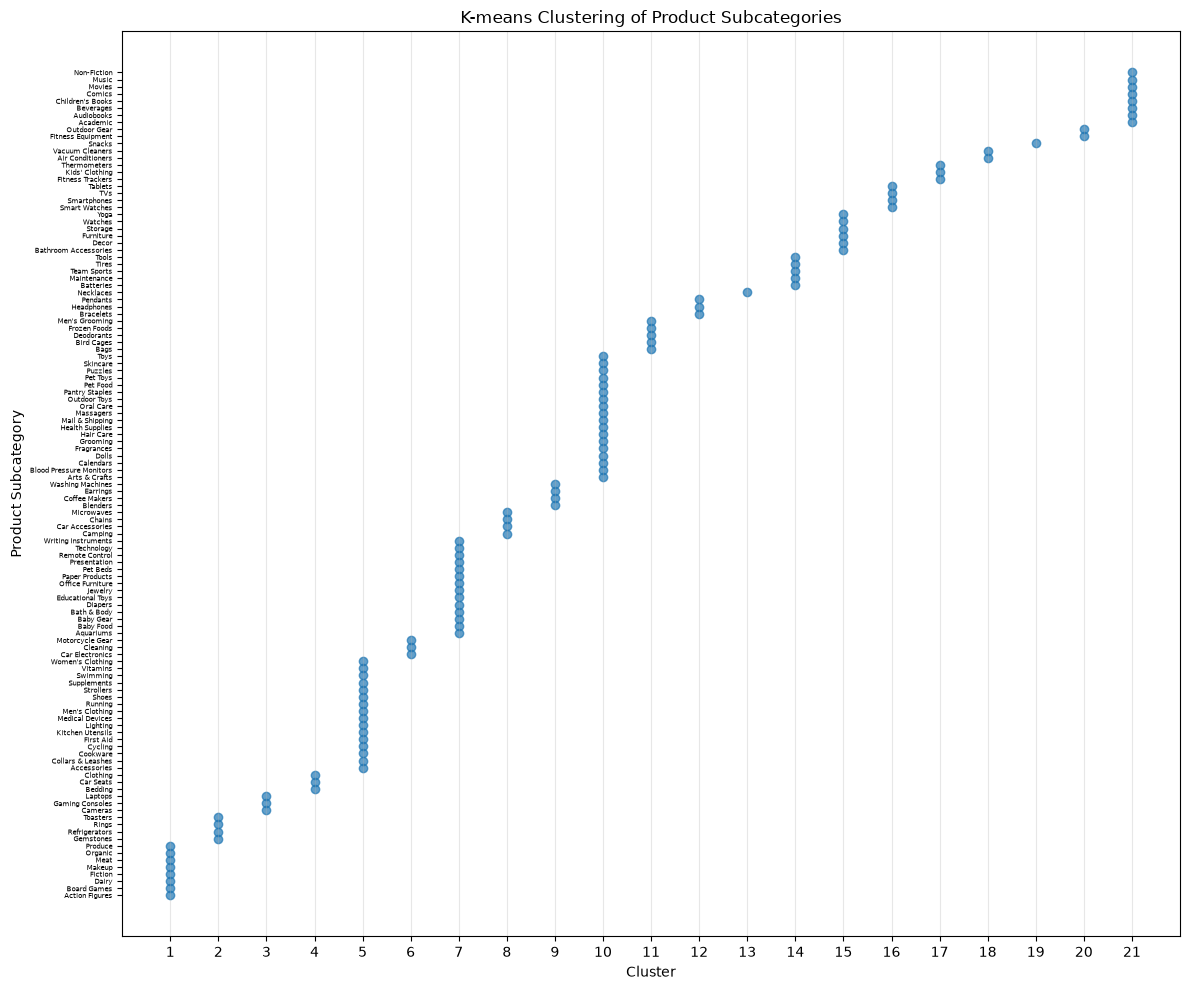

In [160]:
#Visualise Kmeans clustering.
plt.figure(figsize=(12, 10))

plt.scatter(
    groups['group'],
    range(len(groups)),
    alpha=0.7
)

plt.yticks(
    range(len(groups)),
    groups['product_subcategory'],
    fontsize=5
)

plt.xlabel('Cluster')
plt.ylabel('Product Subcategory')
plt.title('K-means Clustering of Product Subcategories')
plt.xticks(range(1, 22))
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [161]:
#Use silhouette_score to fine-tune no. of cluster.

from sklearn.metrics import silhouette_score

results = []

for k in range(5, 30):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    results.append({
        'n_clusters': k,
        'inertia': model.inertia_,
        'silhouette_score': silhouette_score(X, labels)
    })

silhouette_results = pd.DataFrame(results)

silhouette_results

C:\Users\ringa\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ringa\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ringa\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ringa\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_

,n_clusters,inertia,silhouette_score
0,5,206.620436,0.156322
1,6,198.529015,0.110983
2,7,191.566711,0.098867
3,8,186.987619,0.093260
4,9,179.473525,0.087863
5,10,176.233225,0.077087
6,11,172.562844,0.071947
7,12,169.320851,0.066440
8,13,168.181829,0.053519
9,14,162.217517,0.060375


In [162]:
#Measure inertia of Kmeans. Initial Run show better result.
inertia_2=[]
for k in range (5,30):
    kmeans=KMeans(n_clusters=k, n_init=10, random_state=50)
    kmeans.fit(X)
    inertia_2.append(kmeans.inertia_)

inertia_2

C:\Users\ringa\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ringa\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ringa\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ringa\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_

[206.56340498268395,
 198.14442033051094,
 192.1626344395722,
 186.38952199003705,
 182.98834804566388,
 177.77332912386663,
 174.2312705925863,
 168.69244348227846,
 164.5561794157598,
 164.2615231652978,
 160.1688369763234,
 156.79822110812725,
 154.7410839575719,
 152.96505369256948,
 150.6676565249992,
 145.34911368380543,
 143.70139260636464,
 141.9159479572478,
 139.38915707726554,
 137.75581795050672,
 134.97985895030973,
 131.93527401115367,
 131.21570531949206,
 128.25109699517506,
 127.15533749227815]

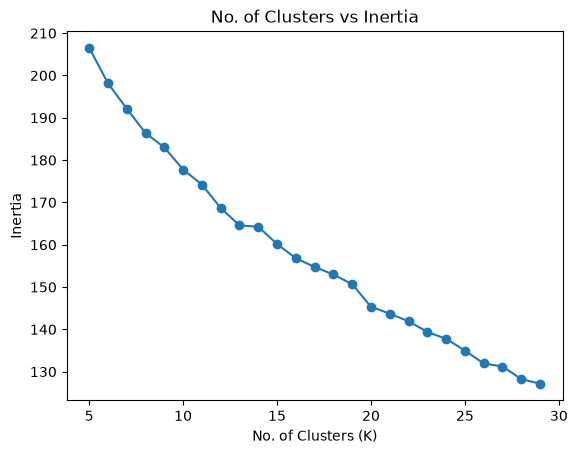

In [163]:
#Visualise inertia of Kmeans with 'Elbow' chart. Initial Run show better result.
import matplotlib.pyplot as plt

inertia_2=pd.Series(inertia_2,index=range(5,30))

inertia_2.plot(marker='o')
plt.xlabel('No. of Clusters (K)')
plt.ylabel('Inertia')
plt.title('No. of Clusters vs Inertia');

In [164]:
#Use Kmeans for clustering N=18 based no revised Silhouette score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# pairwise_group already has product_subcategory as its index
X6 = pairwise_group.copy()

# Choose number of clusters

n_group6 = 5
# Fit K-Means
model6 = KMeans(
    n_clusters=n_group6,
    random_state=42,
    n_init=10
)

label6 = model6.fit_predict(X6)

# Create cluster assignments
group6 = pd.DataFrame({
    'product_subcategory': X6.index,
    'group': label6 + 1
})

# Sort results
group6 = group6.sort_values(
    ['group', 'product_subcategory']
).reset_index(drop=True)

print(group6.to_string())
print(group6.groupby('group').count())

         product_subcategory  group
0                Accessories      1
1              Arts & Crafts      1
2       Bathroom Accessories      1
3                    Bedding      1
4    Blood Pressure Monitors      1
5                  Calendars      1
6                  Car Seats      1
7                   Clothing      1
8          Collars & Leashes      1
9                   Cookware      1
10                   Cycling      1
11                     Decor      1
12                   Diapers      1
13                 First Aid      1
14         Fitness Equipment      1
15          Fitness Trackers      1
16                 Furniture      1
17                  Grooming      1
18          Kitchen Utensils      1
19                  Lighting      1
20           Mail & Shipping      1
21                 Massagers      1
22           Medical Devices      1
23            Men's Clothing      1
24              Outdoor Gear      1
25              Outdoor Toys      1
26                  Pet Beds

C:\Users\ringa\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


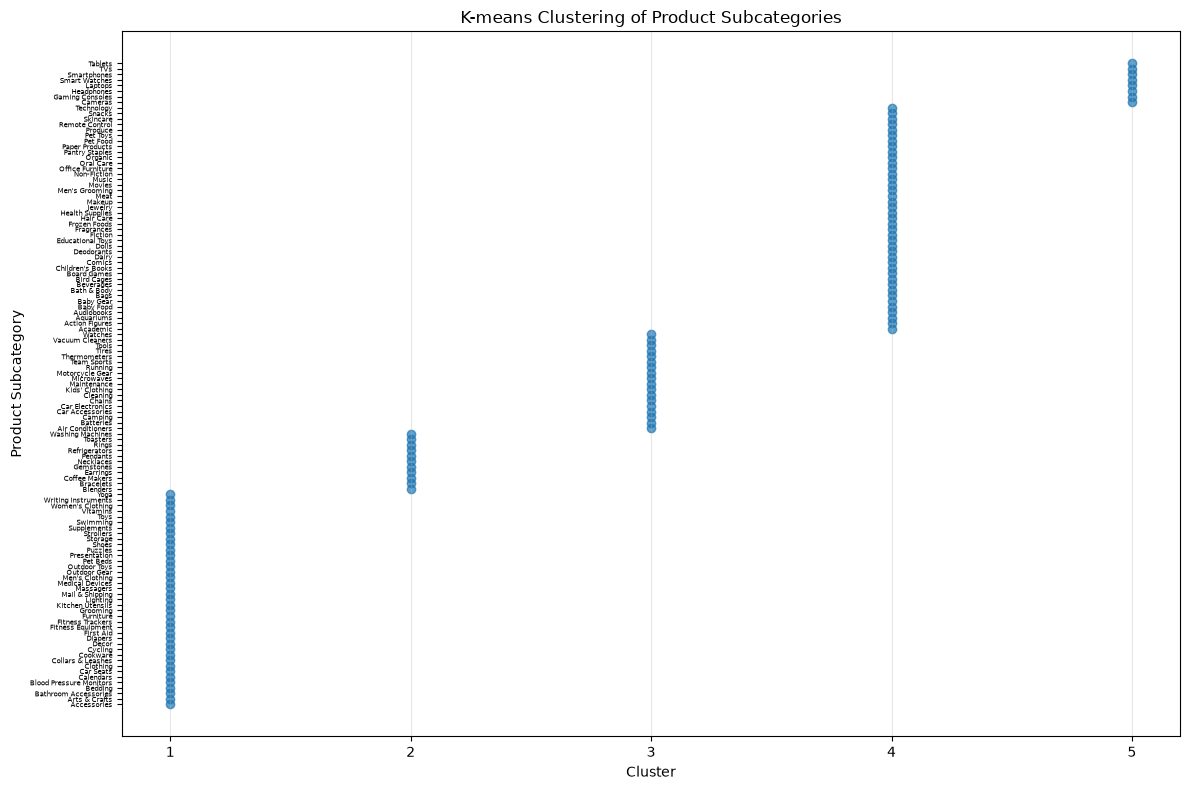

In [165]:
plt.figure(figsize=(12, 8))

plt.scatter(
    group6['group'],
    range(len(group6)),
    alpha=0.7
)

plt.yticks(
    range(len(group6)),
    group6['product_subcategory'],
    fontsize=5
)

plt.xlabel('Cluster')
plt.ylabel('Product Subcategory')
plt.title('K-means Clustering of Product Subcategories')
plt.xticks(range(1, 6))
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

Feature Importance

In [166]:
# Cluster assignments
labels = model6.labels_

# Overall feature means
overall_mean = X6.mean()

# Between-cluster sum of squares
between_ss = pd.Series(0.0, index=X6.columns)

for cluster in range(n_group6):
    cluster_data = X6.iloc[labels == cluster]

    cluster_size = len(cluster_data)
    cluster_mean = cluster_data.mean()

    between_ss += (
        cluster_size * (cluster_mean - overall_mean) ** 2
    )

# Total sum of squares
total_ss = ((X6 - overall_mean) ** 2).sum()

# Feature importance: proportion of variation explained by clusters
feature_importance = (
    between_ss / total_ss
).sort_values(ascending=False)

print(feature_importance.to_string())

product_cost_y                                 0.945903
discount_amount_y                              0.930318
gross_sales_y                                  0.928081
net_sales_y                                    0.927100
unit_price_y                                   0.926584
tax_amount_y                                   0.926583
loyalty_points_earned                          0.923489
loyalty_points_redeemed                        0.921166
customer_lifetime_value                        0.876938
profit_y                                       0.862641
profit_margin_percentage                       0.841794
sub_profit_margin                              0.841370
profit_margin                                  0.786918
brand_Google                                   0.661100
brand_HP                                       0.630571
brand_OnePlus                                  0.586462
brand_Sony                                     0.568834
brand_Apple                                    0

In [121]:
import pandas as pd

# Get cluster centroids
centroids = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=X6.columns
)

# Calculate how much each feature varies across clusters
feature_importance = (
    centroids.max(axis=0) - centroids.min(axis=0)
).sort_values(ascending=False)

feature_importance = feature_importance.rename(
    'Centroid Range'
)

print(feature_importance)

sub_profit_margin           4.331076
unit_price_y                3.709390
product_cost_y              3.037794
net_sales_y                 3.009044
gross_sales_y               2.956077
                              ...   
customer_type_New           0.002830
is_repeat_customer_False    0.002830
coupon_code_SAVE33          0.002801
coupon_code_SAVE28          0.002739
order_status_Completed      0.000000
Name: Centroid Range, Length: 429, dtype: float64


Use PCA for dimensionality redcution and Visualisation

In [167]:
from sklearn.decomposition import PCA

# Reduce features to 2 principal components
pca6 = PCA(n_components=2)

X6_pca = pca6.fit_transform(X6)

# Create a DataFrame for visualisation
pca6_df = pd.DataFrame(
    X6_pca,
    columns=['PC1', 'PC2'],
    index=X6.index
)

# Attach original K-Means labels (6 clusters)
pca6_df['Cluster'] = label6 + 1

# Check number of clusters
print(pca6_df['Cluster'].nunique())  # Should print 6

# Make product_subcategory a normal column
pca6_df = pca6_df.reset_index()

pca6_data=pca6_df.groupby('Cluster')[['product_subcategory','PC1','PC2']].sum().sort_values(by='Cluster',ascending=True)
pca6_data
# pca6_df.to_csv("pca6.csv", index=False)

5


,product_subcategory,PC1,PC2
Cluster,,,
1,AccessoriesArts & CraftsBathroom AccessoriesBe...,21.298321,-3.816276
2,BlendersBraceletsCoffee MakersEarringsGemstone...,-31.322449,5.328704
3,Air ConditionersBatteriesCampingCar Accessorie...,-17.765068,-14.207881
4,AcademicAction FiguresAquariumsAudiobooksBaby ...,68.523761,10.541241
5,CamerasGaming ConsolesHeadphonesLaptopsSmart W...,-40.734565,2.154212


In [168]:
#Kmeans Test N=18 using 'combine' dataset.

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# pairwise_group already has product_subcategory as its index
XT = test_group.copy()

# Choose number of clusters

T_group = 5
# Fit K-Means
modelT = KMeans(
    n_clusters=T_group,
    random_state=42,
    n_init=10
)

labelT = modelT.fit_predict(XT)

# Create cluster assignments
groupT = pd.DataFrame({
    'product_subcategory': XT.index,
    'group': labelT + 1
})

# Sort results
groupT = groupT.sort_values(
    ['group', 'product_subcategory']
).reset_index(drop=True)

print(groupT.to_string())

print(groupT.groupby('group').count())

         product_subcategory  group
0                Accessories      1
1                  Aquariums      1
2              Arts & Crafts      1
3                  Baby Gear      1
4       Bathroom Accessories      1
5                    Bedding      1
6    Blood Pressure Monitors      1
7                  Calendars      1
8                  Car Seats      1
9                   Clothing      1
10         Collars & Leashes      1
11                  Cookware      1
12                   Cycling      1
13                     Decor      1
14                   Diapers      1
15                     Dolls      1
16                 First Aid      1
17         Fitness Equipment      1
18          Fitness Trackers      1
19                 Furniture      1
20                  Grooming      1
21          Kitchen Utensils      1
22                  Lighting      1
23           Mail & Shipping      1
24                 Massagers      1
25           Medical Devices      1
26            Men's Clothing

C:\Users\ringa\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Measure similarity of clustering from Train and Test Data.

In [169]:
from sklearn.metrics import adjusted_rand_score

comparison = group6.merge(
    groupT,
    on='product_subcategory',
    suffixes=('_original', '_test'),
    validate='one_to_one'
)

ari = adjusted_rand_score(
    comparison['group_original'],
    comparison['group_test']
)

print(f"Adjusted Rand Index: {ari:.4f}")

Adjusted Rand Index: 0.8851


Market basket analysis using train/test orders

In [ ]:
%pip install mlxtend

In [170]:
import pandas as pd
import zipfile

from sklearn.model_selection import train_test_split
from mlxtend.frequent_patterns import apriori, association_rules

# Use your EXISTING test transactions; do not split again
test_transactions = test_level.copy()

# Keep completed orders only, if order_status is available
if 'order_status' in test_transactions.columns:
    test_transactions = test_transactions[
        test_transactions['order_status'].str.lower() == 'completed'
    ].copy()

# One row per order-product subcategory
test_transactions = test_transactions[
    ['order_id', 'product_subcategory']
].dropna().drop_duplicates()

test_transactions.head()
test_transactions.shape

(64874, 2)

Step 2 — Build the test basket matrix
Each row represents an order; each column represents a product subcategory. True means the order included that subcategory.

In [171]:
test_basket = pd.crosstab(
    test_transactions['order_id'],
    test_transactions['product_subcategory']
).gt(0)

print("Number of test orders:", len(test_basket))
print("Number of subcategories:", test_basket.shape[1])

test_basket.head()

Number of test orders: 22712
Number of subcategories: 117


product_subcategory,Academic,Accessories,Action Figures,Air Conditioners,Aquariums,Arts & Crafts,Audiobooks,Baby Food,Baby Gear,Bags,...,Toasters,Tools,Toys,Vacuum Cleaners,Vitamins,Washing Machines,Watches,Women's Clothing,Writing Instruments,Yoga
order_id,,,,,,,,,,,,,,,,,,,,,
ORD-100027,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
ORD-100033,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
ORD-100057,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
ORD-100137,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
ORD-100282,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


Step 3 — Learn association rules from training transactions
Market basket analysis should learn rules on the training orders, then evaluate those rules on the test orders.

In [187]:
merged_mba

,order_id,order_status,sales_channel,customer_type,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,...,unit_price_y,product_rating,customer_age_y,gender_y,customer_segment_y,region_y,customer_postal_code_y,customer_acquisition_cost,profit_margin,sub_profit_margin
0,ORD-301242,Completed,Mobile App,Loyal,Digital Wallet,Paid,USD,Standard,WH-003,3.0,...,244.40,4.8,55,Male,Consumer,South,86040,73.06,0.489144,0.463267
1,ORD-301242,Completed,Mobile App,Loyal,Digital Wallet,Paid,USD,Standard,WH-003,3.0,...,287.13,3.0,55,Male,Consumer,South,86040,73.06,0.291347,0.474769
2,ORD-773460,Completed,Website,Loyal,Debit Card,Pending,EUR,Economy,WH-005,10.0,...,754.80,3.5,26,Male,Premium,South,62538,67.27,-0.034304,0.424069
3,ORD-773460,Completed,Website,Loyal,Debit Card,Pending,EUR,Economy,WH-005,10.0,...,31.36,4.0,26,Male,Premium,South,62538,67.27,0.437683,0.487763
4,ORD-449374,Completed,Mobile App,Loyal,Cash on Delivery,Paid,USD,Express,WH-015,3.0,...,6.31,3.0,69,Female,Premium,East,19993,52.02,0.645211,0.480969
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
397564,ORD-252033,Completed,Social Media,Loyal,Debit Card,Paid,USD,Same Day,WH-010,1.0,...,137.53,3.2,46,Female,Consumer,Central,84607,20.33,0.415773,0.460776
397565,ORD-252033,Completed,Social Media,Loyal,Debit Card,Paid,USD,Same Day,WH-010,1.0,...,118.96,2.8,46,Female,Consumer,Central,84607,20.33,0.498482,0.506948
397566,ORD-252033,Completed,Social Media,Loyal,Debit Card,Paid,USD,Same Day,WH-010,1.0,...,52.50,3.1,46,Female,Consumer,Central,84607,20.33,0.475724,0.501374
397567,ORD-528577,Completed,Mobile App,Loyal,Digital Wallet,Paid,USD,Standard,WH-013,5.0,...,1120.49,4.8,28,Male,Consumer,West,88333,16.04,0.489125,0.342736


In [190]:
# 1. Prepare training transactions, add order_id back in Cell 
train_transactions = merged_mba[
    ['order_id', 'product_subcategory']
].dropna().drop_duplicates()

# 2. Convert transactions into a basket matrix
train_basket = pd.crosstab(
    train_transactions['order_id'],
    train_transactions['product_subcategory']
).gt(0)

# 3. Find frequent itemsets
freq = apriori(
    train_basket,
    min_support=0.001,
    use_colnames=True
)

# 4. Generate association rules
rules = association_rules(
    freq,
    metric='lift',
    min_threshold=1.0
)

# 5. Display the strongest rules
rules = rules.sort_values(
    by='lift',
    ascending=False
)

rules.head(10)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
132,(Calendars),(Outdoor Toys),0.030942,0.026319,0.001035,0.033440,1.270568,1.0,0.000220,1.007367,0.219750,0.018403,0.007314,0.036377
133,(Outdoor Toys),(Calendars),0.026319,0.030942,0.001035,0.039314,1.270568,1.0,0.000220,1.008715,0.218707,0.018403,0.008639,0.036377
285,(Fragrances),(Music),0.036424,0.024184,0.001112,0.030523,1.262133,1.0,0.000231,1.006539,0.215541,0.018686,0.006496,0.038247
284,(Music),(Fragrances),0.024184,0.036424,0.001112,0.045972,1.262133,1.0,0.000231,1.010008,0.212838,0.018686,0.009909,0.038247
162,(Car Electronics),(TVs),0.031470,0.031757,0.001233,0.039175,1.233584,1.0,0.000233,1.007720,0.195506,0.019886,0.007661,0.038998
163,(TVs),(Car Electronics),0.031757,0.031470,0.001233,0.038821,1.233584,1.0,0.000233,1.007648,0.195564,0.019886,0.007590,0.038998
0,(Beverages),(Action Figures),0.033936,0.029159,0.001211,0.035680,1.223623,1.0,0.000221,1.006762,0.189175,0.019566,0.006716,0.038602
1,(Action Figures),(Beverages),0.029159,0.033936,0.001211,0.041525,1.223623,1.0,0.000221,1.007918,0.188244,0.019566,0.007856,0.038602
77,(Beverages),(Board Games),0.033936,0.029181,0.001211,0.035680,1.222700,1.0,0.000221,1.006739,0.188536,0.019559,0.006694,0.038587
76,(Board Games),(Beverages),0.029181,0.033936,0.001211,0.041494,1.222700,1.0,0.000221,1.007885,0.187613,0.019559,0.007823,0.038587


In [192]:
import pandas as pd

# Select five unique product pairs from the training results
top_rules = rules.sort_values(
    'lift', ascending=False
).drop_duplicates(
    subset=['antecedents', 'consequents']
).head(5).copy()

# Build the test basket using held-out orders
test_transactions = test_level[
    ['order_id', 'product_subcategory']
].dropna().drop_duplicates()

test_basket = pd.crosstab(
    test_transactions['order_id'],
    test_transactions['product_subcategory']
).astype(bool)

# Calculate metrics for each rule in the test set
results = []

for _, rule in top_rules.iterrows():
    A = next(iter(rule['antecedents']))
    B = next(iter(rule['consequents']))

    if A not in test_basket.columns or B not in test_basket.columns:
        continue

    has_A = test_basket[A]
    has_B = test_basket[B]

    support_A = has_A.mean()
    support_B = has_B.mean()
    support_AB = (has_A & has_B).mean()

    confidence_test = (
        support_AB / support_A if support_A > 0 else float('nan')
    )
    lift_test = (
        confidence_test / support_B if support_B > 0 else float('nan')
    )

    results.append({
        'Rule': f'{A} → {B}',
        'Training Support': rule['support'],
        'Training Confidence': rule['confidence'],
        'Training Lift': rule['lift'],
        'Test Support': support_AB,
        'Test Confidence': confidence_test,
        'Test Lift': lift_test,
        'Test Orders Together': int((has_A & has_B).sum())
    })

validation_df = pd.DataFrame(results)

validation_df.round(4)

,Rule,Training Support,Training Confidence,Training Lift,Test Support,Test Confidence,Test Lift,Test Orders Together
0,Calendars → Outdoor Toys,0.0010,0.0334,1.2706,0.0007,0.0233,0.8515,17
1,Outdoor Toys → Calendars,0.0010,0.0393,1.2706,0.0007,0.0273,0.8515,17
2,Fragrances → Music,0.0011,0.0305,1.2621,0.0006,0.0177,0.7477,14
3,Music → Fragrances,0.0011,0.0460,1.2621,0.0006,0.0260,0.7477,14
4,Car Electronics → TVs,0.0012,0.0392,1.2336,0.0009,0.0299,0.9610,21


In [193]:
rules = association_rules(
    freq,
    metric='confidence',
    min_threshold=0.1
)

print("Number of rules:", len(rules))
rules.head(10)

Number of rules: 0


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski


Saving PCA result for Visualisation

In [ ]:
# quad3=pd.read_csv('C:/Codefiles/Content/biquadrant3.csv')
# pca6_df=pca6_df.merge(quad, on='product_subcategory', how='left')
pca6_df

In [ ]:
pca6_df.to_csv("pca.csv", index=False)
# pca_df

Initial Run with N=6 show better result.

In [ ]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=pca6_df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='tab10',
    alpha=0.5,
    s=80
)

for _, row in pca6_df.iterrows():
    plt.annotate(
        row['product_subcategory'],
        (row['PC1'], row['PC2']),
        fontsize=8,
        alpha=0.8
    )

plt.title('K-Means: 18 Clusters Visualised Using PCA')
plt.show()

In [ ]:
#6 clusters based on highest silhouette score.
grouped_subcategories = (
    group6.groupby('group')['product_subcategory']
    .apply(list)
)

for group_id, subcategories in grouped_subcategories.items():
    print(f"Group {group_id}: {', '.join(subcategories)}")

In [ ]:
#Measure inertia of Kmeans. Initial Run show better result.
inertia_2=[]
for k in range (5,30):
    kmeans=KMeans(n_clusters=k, n_init=10, random_state=50)
    kmeans.fit(X)
    inertia_2.append(kmeans.inertia_)

inertia_2

In [ ]:
#Visualise inertia of Kmeans with 'Elbow' chart. Initial Run show better result.
import matplotlib.pyplot as plt

inertia_2=pd.Series(inertia_2,index=range(5,30))

inertia_2.plot(marker='o')
plt.xlabel('No. of Clusters (K)')
plt.ylabel('Inertia')
plt.title('No. of Clusters vs Inertia');

In [ ]:
#Use silhouette_score to fine-tune no. of cluster.

from sklearn.metrics import silhouette_score

results = []

for k in range(5, 30):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    results.append({
        'n_clusters': k,
        'inertia': model.inertia_,
        'silhouette_score': silhouette_score(X, labels)
    })

silhouette_results = pd.DataFrame(results)

silhouette_results

In [ ]:
grouped_subcategories = (
    group6.groupby('group')['product_subcategory']
    .apply(list)
)

for group_id, subcategories in grouped_subcategories.items():
    print(f"Group {group_id}: {', '.join(subcategories)}")